# Lab 1 – Partie 2 : Classification multi-classes (Maintenance prédictive)
Prédire le **type de panne** (`Failure Type`) d'une machine à partir de capteurs. Dataset très déséquilibré → SMOTE.

In [16]:
%pip install -q kagglehub imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [17]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, torch, torch.nn as nn
from collections import defaultdict
from torch.utils.data import TensorDataset, DataLoader
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin
import warnings; warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", DEVICE)

def build_mlp(d_in, d_out, hidden, dropout=0.0, batchnorm=False):
    layers, prev = [], d_in
    for h in hidden:
        layers.append(nn.Linear(prev, h))
        if batchnorm: layers.append(nn.BatchNorm1d(h))
        layers.append(nn.ReLU())
        if dropout > 0: layers.append(nn.Dropout(dropout))
        prev = h
    layers.append(nn.Linear(prev, d_out))
    return nn.Sequential(*layers)

OPTIMIZERS = {
    "adam":    lambda p, lr, wd: torch.optim.Adam(p, lr=lr, weight_decay=wd),
    "adamw":   lambda p, lr, wd: torch.optim.AdamW(p, lr=lr, weight_decay=wd),
    "sgd":     lambda p, lr, wd: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=wd),
    "rmsprop": lambda p, lr, wd: torch.optim.RMSprop(p, lr=lr, weight_decay=wd),
}

class _TorchBase(BaseEstimator):
    """Wrapper PyTorch compatible scikit-learn (fit / predict / score) -> utilisable dans GridSearchCV."""
    def __init__(self, hidden=(64, 32), lr=1e-3, optimizer="adam", epochs=20, batch_size=256,
                 dropout=0.0, weight_decay=0.0, batchnorm=False, patience=0, use_class_weight=False):
        self.hidden = hidden; self.lr = lr; self.optimizer = optimizer; self.epochs = epochs
        self.batch_size = batch_size; self.dropout = dropout; self.weight_decay = weight_decay
        self.batchnorm = batchnorm; self.patience = patience; self.use_class_weight = use_class_weight

    def _forward(self, X):
        self.model_.eval(); outs = []
        with torch.no_grad():
            for i in range(0, len(X), 8192):
                outs.append(self.model_(torch.as_tensor(X[i:i + 8192], dtype=torch.float32, device=DEVICE)))
        return torch.cat(outs)

    def _eval(self, X, yt):
        out = self._forward(X)
        return self._loss(out, yt).item(), self._metric(out, yt).item()

    def fit(self, X, y, X_val=None, y_val=None):
        X = np.asarray(X, dtype=np.float32)
        yt = self._setup(y)
        torch.manual_seed(SEED)
        self.model_ = build_mlp(X.shape[1], self.n_out_, self.hidden, self.dropout, self.batchnorm).to(DEVICE)
        opt = OPTIMIZERS[self.optimizer](self.model_.parameters(), self.lr, self.weight_decay)
        loader = DataLoader(TensorDataset(torch.as_tensor(X, device=DEVICE), yt),
                            batch_size=self.batch_size, shuffle=True, drop_last=self.batchnorm)
        self.history_ = defaultdict(list); best, wait, best_state = np.inf, 0, None
        if X_val is not None:
            X_val = np.asarray(X_val, dtype=np.float32); yv = self._encode(y_val)
        for ep in range(self.epochs):
            self.model_.train()
            for xb, yb in loader:
                opt.zero_grad(); self._loss(self.model_(xb), yb).backward(); opt.step()
            trl, trm = self._eval(X, yt)
            self.history_["train_loss"].append(trl); self.history_["train_metric"].append(trm)
            if X_val is not None:
                vl, vm = self._eval(X_val, yv)
                self.history_["val_loss"].append(vl); self.history_["val_metric"].append(vm)
                if self.patience > 0:  # early stopping
                    if vl < best - 1e-6:
                        best, wait = vl, 0
                        best_state = {k: v.clone() for k, v in self.model_.state_dict().items()}
                    else:
                        wait += 1
                        if wait >= self.patience: break
        if best_state is not None: self.model_.load_state_dict(best_state)
        return self

class TorchRegressor(RegressorMixin, _TorchBase):
    def _encode(self, y): return torch.as_tensor(np.asarray(y, dtype=np.float32).reshape(-1, 1), device=DEVICE)
    def _setup(self, y): self.n_out_ = 1; return self._encode(y)
    def _loss(self, out, yb): return nn.functional.mse_loss(out, yb)
    def _metric(self, out, yb): return 1 - ((yb - out) ** 2).sum() / ((yb - yb.mean()) ** 2).sum()   # R2
    def predict(self, X): return self._forward(np.asarray(X, dtype=np.float32)).cpu().numpy().ravel()

class TorchClassifier(ClassifierMixin, _TorchBase):
    def _encode(self, y): return torch.as_tensor(np.searchsorted(self.classes_, np.asarray(y)), dtype=torch.long, device=DEVICE)
    def _setup(self, y):
        self.classes_ = np.unique(y); self.n_out_ = len(self.classes_)
        yt = self._encode(y)
        if self.use_class_weight:
            cnt = torch.bincount(yt, minlength=self.n_out_).float()
            self.weights_ = (len(yt) / (self.n_out_ * cnt.clamp(min=1))).to(DEVICE)
        else:
            self.weights_ = None
        return yt
    def _loss(self, out, yb): return nn.functional.cross_entropy(out, yb, weight=self.weights_)
    def _metric(self, out, yb): return (out.argmax(1) == yb).float().mean()   # accuracy
    def predict(self, X): return self.classes_[self._forward(np.asarray(X, dtype=np.float32)).argmax(1).cpu().numpy()]

def plot_history(h, metric_name, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(h["train_loss"], label="Train"); ax[0].plot(h["val_loss"], label="Test")
    ax[0].set(title=f"{title} Loss / Epochs", xlabel="Epoch", ylabel="Loss"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h["train_metric"], label="Train"); ax[1].plot(h["val_metric"], label="Test")
    ax[1].set(title=f"{title} {metric_name} / Epochs", xlabel="Epoch", ylabel=metric_name); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

Device : cpu


In [18]:
import kagglehub
path = kagglehub.dataset_download("shivamb/machine-predictive-maintenance-classification")
df = pd.read_csv(f"{path}/predictive_maintenance.csv"); df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


## 1. Pré-traitement / nettoyage

In [19]:
print(df.shape); df.info()
print("Manquants :", df.isna().sum().sum(), "| Doublons :", df.duplicated().sum())
df.columns = [c.split(" [")[0].replace(" ", "_") for c in df.columns]   # noms de colonnes propres
print(df.columns.tolist())
print(df["Failure_Type"].value_counts())

(10000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
Manquants : 0 | Doublons : 0
['UDI', 'Product_ID', 'Type', 'Air_temperature', 'Process_temperature', 'Rotational_speed', 'Torque', 'Tool_wear', 'Target', 'Failure_Type'

In [20]:
# Incohérences connues : Target=0 mais panne déclarée (dont "Random Failures"), ou Target=1 sans panne
bad = ((df.Target == 0) & (df.Failure_Type != "No Failure")) | ((df.Target == 1) & (df.Failure_Type == "No Failure"))
print("Lignes incohérentes :", bad.sum()); df = df[~bad].copy()

# Suppression des identifiants et de Target (fuite de la cible : Target = 1 <=> panne)
df = df.drop(columns=["UDI", "Product_ID", "Target"])
df["Type"] = df["Type"].map({"L": 0, "M": 1, "H": 2})   # variable ordinale (qualité)

# Outliers : détection IQR (information, on les conserve : ce sont souvent les pannes)
num = ["Air_temperature", "Process_temperature", "Rotational_speed", "Torque", "Tool_wear"]
for c in num:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    print(c, "outliers IQR :", ((df[c] < q1 - 1.5 * i) | (df[c] > q3 + 1.5 * i)).sum())
print(df.Failure_Type.value_counts())

Lignes incohérentes : 27
Air_temperature outliers IQR : 0
Process_temperature outliers IQR : 0
Rotational_speed outliers IQR : 418
Torque outliers IQR : 70
Tool_wear outliers IQR : 0
Failure_Type
No Failure                  9643
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Name: count, dtype: int64


## 2. EDA

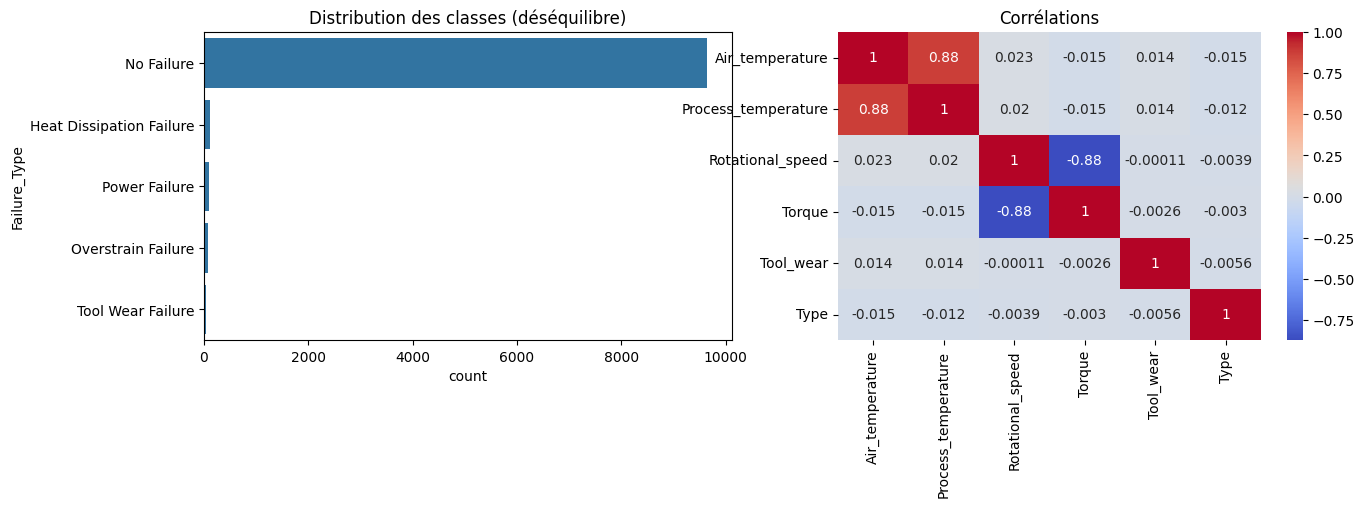

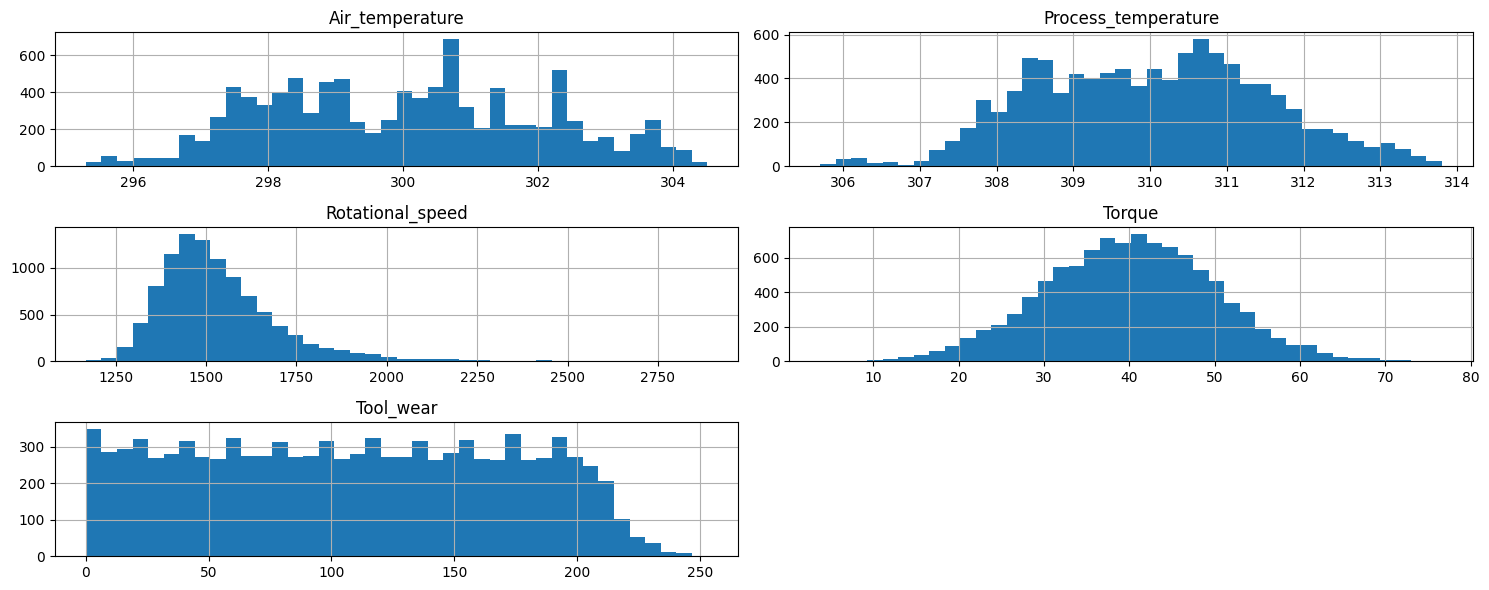

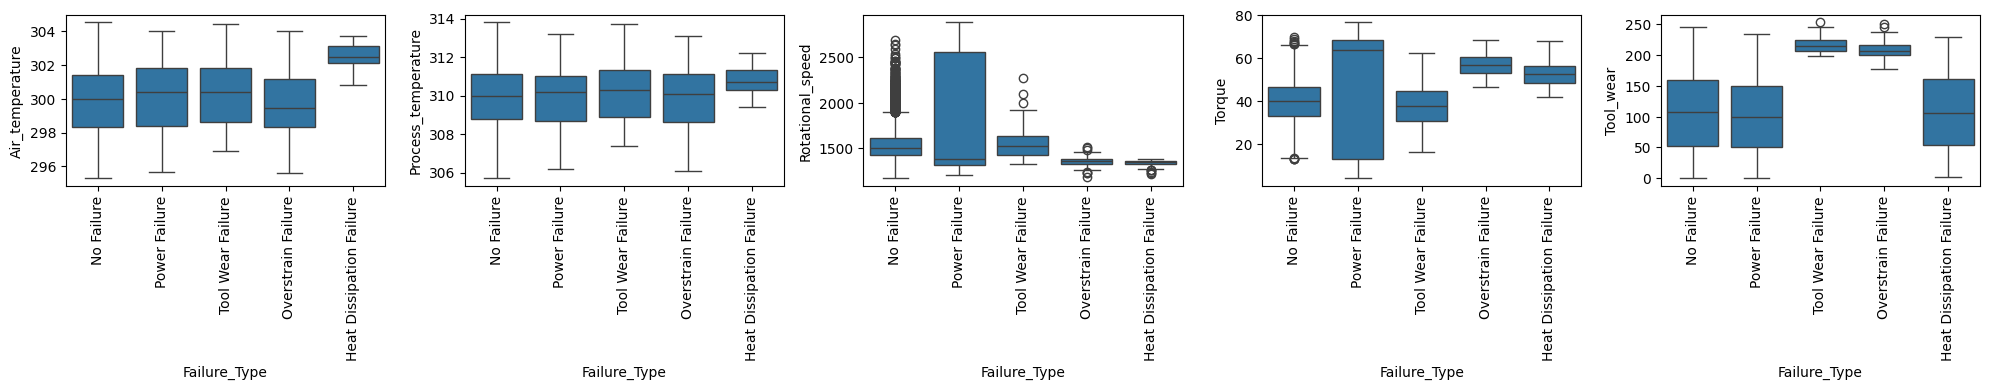

Failure_Type,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Tool Wear Failure
Type,,,,,
0,74,5753,73,59,25
1,30,2912,4,31,14
2,8,978,1,5,6


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.countplot(y="Failure_Type", data=df, ax=ax[0], order=df.Failure_Type.value_counts().index); ax[0].set_title("Distribution des classes (déséquilibre)")
sns.heatmap(df[num + ["Type"]].corr(), annot=True, cmap="coolwarm", ax=ax[1]); ax[1].set_title("Corrélations")
plt.show()
df[num].hist(bins=40, figsize=(15, 6)); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for a, c in zip(ax, num): sns.boxplot(x="Failure_Type", y=c, data=df, ax=a); a.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()
pd.crosstab(df.Type, df.Failure_Type)

**Observations EDA / nettoyage**
- 10 000 lignes, aucune valeur manquante ni doublon. 27 lignes incohérentes (dont les 18 « Random Failures », étiquetées `Target=0`) ont été supprimées ; il reste **9 973 lignes et 5 classes**. `UDI`, `Product_ID` et `Target` sont retirés (`Target` révèle directement la cible → fuite).
- **Fort déséquilibre** : « No Failure » ≈ 96,7 % ; les classes de pannes comptent 112 (Heat), 95 (Power), 78 (Overstrain) et 45 (Tool Wear) exemples.
- Outliers IQR : 418 sur `Rotational_speed` et 70 sur `Torque`. Ils sont conservés, car ils correspondent souvent à de vraies pannes.
- Les boxplots montrent des signatures par type de panne : *Heat Dissipation* → température de l'air plus élevée et vitesse de rotation basse (~1 350 rpm) ; *Overstrain* → couple élevé et usure d'outil élevée (~200+ min) ; *Power Failure* → très forte dispersion du couple et de la vitesse ; *Tool Wear* → usure d'outil concentrée autour de 200-250 min, mais ce domaine chevauche celui d'autres classes (peu séparable).

## 3. Split, normalisation et augmentation (SMOTE)
Split **stratifié** d'abord ; scaler et SMOTE ajustés **uniquement sur le train** (sinon fuite de données).

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from imblearn.over_sampling import SMOTE

le = LabelEncoder(); y = le.fit_transform(df.Failure_Type); X = df.drop(columns="Failure_Type")
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
sc = StandardScaler(); X_tr = sc.fit_transform(X_tr); X_te = sc.transform(X_te)

X_res, y_res = SMOTE(k_neighbors=3, random_state=SEED).fit_resample(X_tr, y_tr)
print("Avant :", dict(zip(le.classes_, np.bincount(y_tr)))); print("Après :", dict(zip(le.classes_, np.bincount(y_res))))

Avant : {'Heat Dissipation Failure': np.int64(90), 'No Failure': np.int64(7714), 'Overstrain Failure': np.int64(62), 'Power Failure': np.int64(76), 'Tool Wear Failure': np.int64(36)}
Après : {'Heat Dissipation Failure': np.int64(7714), 'No Failure': np.int64(7714), 'Overstrain Failure': np.int64(7714), 'Power Failure': np.int64(7714), 'Tool Wear Failure': np.int64(7714)}


## 4. MLP de base

In [23]:
base = TorchClassifier(hidden=(64, 32), lr=1e-3, optimizer="adam", epochs=30, batch_size=256)
base.fit(X_res, y_res, X_te, y_te)
print("Acc train :", base.score(X_tr, y_tr), "| Acc test :", base.score(X_te, y_te))

Acc train : 0.9682877914264226 | Acc test : 0.9548872180451128


## 5. GridSearchCV
On utilise un `Pipeline` **imblearn** (SMOTE à l'intérieur de chaque fold → pas de fuite) et le score `f1_macro` (l'accuracy est trompeuse avec des classes déséquilibrées).

In [24]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
pipe = ImbPipeline([("smote", SMOTE(k_neighbors=3, random_state=SEED)), ("clf", TorchClassifier(batch_size=256))])
param_grid = {
    "clf__lr": [1e-3, 1e-2],
    "clf__optimizer": ["adam", "rmsprop"],
    "clf__hidden": [(32, 16), (64, 32), (128, 64, 32)],
    "clf__epochs": [20, 40],
}
grid = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="f1_macro", n_jobs=1, verbose=1)
grid.fit(X_tr, y_tr)
best_params = {k.replace("clf__", ""): v for k, v in grid.best_params_.items()}
print("Meilleurs hyperparamètres :", best_params, "| F1 macro CV :", grid.best_score_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Meilleurs hyperparamètres : {'epochs': 40, 'hidden': (128, 64, 32), 'lr': 0.01, 'optimizer': 'adam'} | F1 macro CV : 0.6865989119945722


## 6. Entraînement final + courbes Loss/Epochs et Accuracy/Epochs

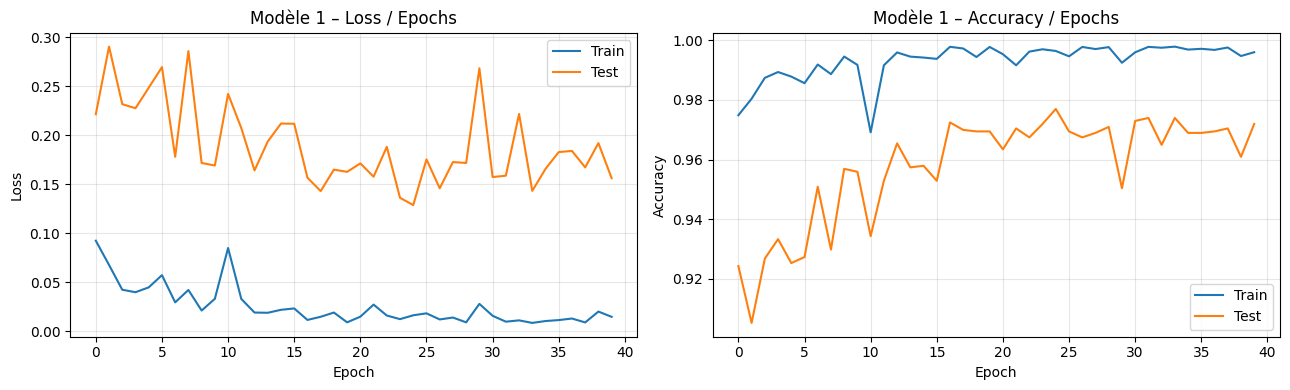

In [25]:
best = TorchClassifier(**{**best_params, "batch_size": 256}).fit(X_res, y_res, X_te, y_te)
plot_history(best.history_, "Accuracy", "Modèle 1 –")

### Interprétation – Modèle 1 (Adam, lr=0,01, couches 128-64-32, 40 epochs)
- **Convergence** : la loss train décroît de ≈ 0,09 à ≈ 0,01 ; l'accuracy train atteint ≈ 99,6 %.
- **Sur-apprentissage net** : la loss test reste entre ≈ 0,13 et 0,29 et oscille fortement, avec un écart important par rapport au train ; l'accuracy test plafonne autour de 97 % avec des variations de ±1 à 2 points d'une epoch à l'autre. Les classes rares, très peu représentées en test (9 à 22 exemples), rendent la courbe test bruitée.
- **Attention à la comparaison** : la courbe train est calculée sur des données *équilibrées par SMOTE* (7 714 exemples par classe) alors que la courbe test est calculée sur des données *réelles déséquilibrées*. L'écart de niveau d'accuracy n'est donc pas uniquement dû au sur-apprentissage.
- Le modèle apprend rapidement (≈ 92 % de test dès la première epoch), ce qui est normal : il suffit de prédire « No Failure » pour obtenir ≈ 96 %. L'accuracy est donc trompeuse ; il faut regarder le F1 macro et la sensibilité.

## 7. Métriques (accuracy, sensibilité, spécificité, précision, F1) – train et test

,modèle/jeu,accuracy,précision (macro),sensibilité/recall (macro),spécificité (macro),F1 (macro),F1 (pondéré)
0,Train,0.9882,0.7895,0.9920,0.9969,0.8740,0.9891
1,Test,0.9719,0.5963,0.7952,0.9650,0.6746,0.9749


                          precision    recall  f1-score   support

Heat Dissipation Failure       0.64      0.95      0.76        22
              No Failure       0.99      0.98      0.99      1929
      Overstrain Failure       0.64      0.88      0.74        16
           Power Failure       0.58      0.95      0.72        19
       Tool Wear Failure       0.13      0.22      0.17         9

                accuracy                           0.97      1995
               macro avg       0.60      0.80      0.67      1995
            weighted avg       0.98      0.97      0.97      1995



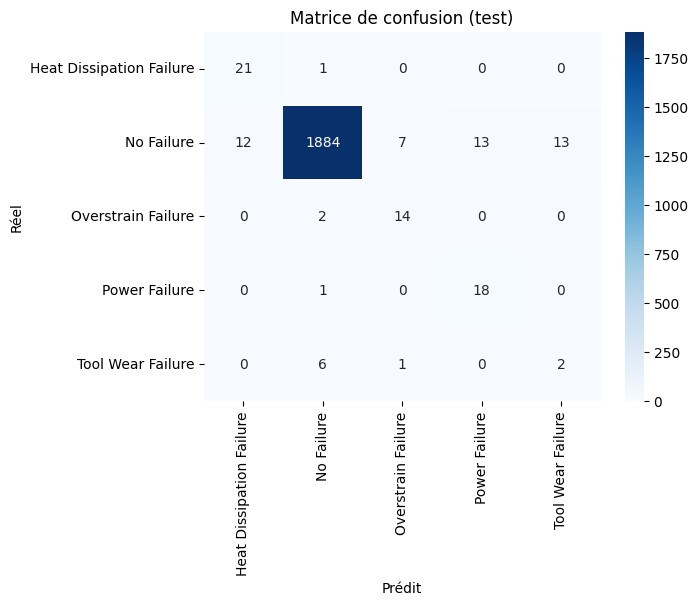

In [26]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

def full_metrics(m, X, y_true, name):
    p = m.predict(X); cm = confusion_matrix(y_true, p, labels=range(len(le.classes_)))
    TP = np.diag(cm); FP = cm.sum(0) - TP; FN = cm.sum(1) - TP; TN = cm.sum() - (TP + FP + FN)
    return {"modèle/jeu": name, "accuracy": accuracy_score(y_true, p),
            "précision (macro)": precision_score(y_true, p, average="macro", zero_division=0),
            "sensibilité/recall (macro)": recall_score(y_true, p, average="macro", zero_division=0),
            "spécificité (macro)": np.mean(TN / (TN + FP)),
            "F1 (macro)": f1_score(y_true, p, average="macro", zero_division=0),
            "F1 (pondéré)": f1_score(y_true, p, average="weighted", zero_division=0)}

display(pd.DataFrame([full_metrics(best, X_tr, y_tr, "Train"), full_metrics(best, X_te, y_te, "Test")]).round(4))
print(classification_report(y_te, best.predict(X_te), target_names=le.classes_, zero_division=0))
cm = confusion_matrix(y_te, best.predict(X_te))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_); plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Matrice de confusion (test)"); plt.show()

## 8. Régularisation et comparaison

,accuracy,précision (macro),sensibilité/recall (macro),spécificité (macro),F1 (macro),F1 (pondéré)
modèle/jeu,,,,,,
Baseline,0.9719,0.5963,0.7952,0.9650,0.6746,0.9749
Dropout 0.3,0.9439,0.5351,0.8577,0.9711,0.6270,0.9584
L2 (wd=1e-3),0.9529,0.5722,0.8319,0.9641,0.6522,0.9643
BatchNorm,0.9614,0.5750,0.7783,0.9571,0.6468,0.9684
Early stopping,0.9769,0.6906,0.7831,0.9602,0.7251,0.9798
Combiné,0.9263,0.5221,0.8769,0.9705,0.6138,0.9489


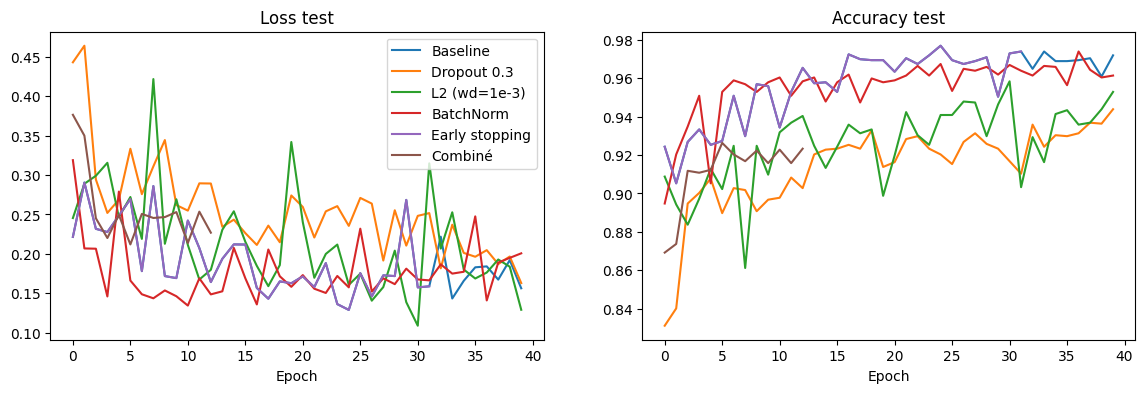

In [27]:
bp = {**best_params, "batch_size": 256, "epochs": max(best_params["epochs"], 40)}
configs = {
    "Baseline": {},
    "Dropout 0.3": {"dropout": 0.3},
    "L2 (wd=1e-3)": {"weight_decay": 1e-3},
    "BatchNorm": {"batchnorm": True},
    "Early stopping": {"patience": 7},
    "Combiné": {"dropout": 0.2, "weight_decay": 1e-4, "batchnorm": True, "patience": 7},
}
rows, hist = [], {}
for name, extra in configs.items():
    m = TorchClassifier(**{**bp, **extra}).fit(X_res, y_res, X_te, y_te)
    rows.append(full_metrics(m, X_te, y_te, name)); hist[name] = m.history_
res = pd.DataFrame(rows).set_index("modèle/jeu"); display(res.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for n, h in hist.items(): ax[0].plot(h["val_loss"], label=n); ax[1].plot(h["val_metric"], label=n)
ax[0].set(title="Loss test", xlabel="Epoch"); ax[1].set(title="Accuracy test", xlabel="Epoch"); ax[0].legend(); plt.show()

### Analyse des métriques (modèle 1, test)
- Accuracy 97,2 % mais **F1 macro = 0,675**, précision macro = 0,596, **sensibilité macro = 0,795**, spécificité macro = 0,965.
- Par classe (test) : *Heat Dissipation* F1 0,76 (rappel 0,95), *Overstrain* 0,74 (rappel 0,88), *Power Failure* 0,72 (rappel 0,95), *No Failure* 0,99, mais **Tool Wear Failure F1 = 0,17** (précision 0,13, rappel 0,22).
- SMOTE a fortement augmenté le **rappel** des pannes (≈ 0,9) au prix d'une **précision** plus faible (≈ 0,6) : le modèle détecte presque toutes les pannes mais déclenche des fausses alarmes. Pour la maintenance prédictive, c'est un compromis souvent acceptable (rater une panne coûte plus cher qu'une fausse alerte).
- Écart train/test : F1 macro 0,874 (train) contre 0,675 (test) → sur-apprentissage confirmé.

### Comparaison des techniques de régularisation (partie 2, test)

| Modèle | Accuracy | Précision (macro) | Sensibilité (macro) | Spécificité (macro) | F1 macro |
|---|---|---|---|---|---|
| Baseline | 0,9719 | 0,5963 | 0,7952 | 0,9650 | 0,6746 |
| Dropout 0,3 | 0,9439 | 0,5351 | 0,8577 | 0,9711 | 0,6270 |
| L2 (wd=1e-3) | 0,9529 | 0,5722 | 0,8319 | 0,9641 | 0,6522 |
| BatchNorm | 0,9614 | 0,5750 | 0,7783 | 0,9571 | 0,6468 |
| **Early stopping** | **0,9769** | **0,6906** | 0,7831 | 0,9602 | **0,7251** |
| Combiné | 0,9263 | 0,5221 | **0,8769** | 0,9705 | 0,6138 |

- **Early stopping** est la meilleure technique globale : meilleur F1 macro (0,725 vs 0,675), meilleure accuracy et meilleure précision, en limitant le sur-apprentissage observé sur la courbe test.
- **Dropout, L2 et la version combinée** augmentent la **sensibilité** (jusqu'à 0,877) mais détériorent la précision et l'accuracy : le modèle devient plus « prudent » et prédit plus de pannes, dont beaucoup de fausses alertes. À choisir si l'on privilégie le rappel.
- **BatchNorm** stabilise la loss mais n'améliore pas le F1.
- **Limites** : la classe *Tool Wear Failure* (36 exemples d'entraînement, 9 en test) reste mal détectée. Les points synthétiques de SMOTE se mélangent aux classes voisines, et les résultats varient selon la graine. Pistes : pondération des classes (`use_class_weight=True`), validation croisée plus large, collecte de données supplémentaires, ou seuil de décision ajusté.

## Synthèse personnelle
Cette partie m'a appris à traiter un problème de classification multi-classes très déséquilibré : nettoyer les incohérences, éviter la fuite de données (suppression de `Target`, split stratifié avant standardisation et SMOTE, SMOTE à l'intérieur du pipeline de validation croisée), et utiliser des métriques adaptées (F1 macro, sensibilité, spécificité, matrice de confusion) plutôt que l'accuracy seule, qui atteint 97 % même pour un modèle médiocre sur les classes rares. J'ai aussi constaté que la régularisation provoque un compromis précision/rappel et que l'early stopping a donné le meilleur équilibre ici. Enfin, j'ai appris à intégrer un modèle PyTorch dans `GridSearchCV` via un wrapper scikit-learn.